In [3]:
from pathlib import Path

import numpy as np

arepo_path = Path("/afs/mpa/temp/abinaya3/HVs/remnant_Model_1696_Explosion108_new.txt")

entropy_input_path = Path("remnant_entropy_eosDT.dat")
skip_outer = 0  # Set to 50 to match the example's radial coverage.

with Path(arepo_path).open() as profile:
    for line in profile:
        if line.startswith("# r_inner,"):
            columns = [name.strip() for name in line[1:].split(",")]
            break
    else:
        raise ValueError("Could not find the AREPO column header.")

    data = np.loadtxt(profile, ndmin=2)

mass = data[:, columns.index("mass")]
radius = data[:, columns.index("r_outer")]
density = data[:, columns.index("density")]
temperature = data[:, columns.index("T")]

if not np.all(np.isfinite(radius)) or not np.all(np.diff(radius) > 0):
    raise ValueError("Expected AREPO shells in center-to-surface order.")

for name, values in [
    ("shell mass", mass), ("density", density), ("temperature", temperature)
]:
    if not np.all(np.isfinite(values) & (values > 0)):
        raise ValueError("Expected finite, positive {} values.".format(name))

if not 0 <= skip_outer < len(mass):
    raise ValueError("skip_outer must leave at least one shell.")

# Compute q on the full profile before optionally dropping outer shells.
surface_first_mass = mass[::-1]
q = (np.cumsum(surface_first_mass) - 0.5 * surface_first_mass) / mass.sum()

if not (0 < q[0] <= q[-1] < 1) or not np.all(np.diff(q) > 0):
    raise ValueError("Expected strictly increasing q within (0, 1).")

table = np.column_stack([q, density[::-1], temperature[::-1]])[skip_outer:]

with entropy_input_path.open("x") as output:
    output.write("{}\n".format(len(table)))
    for row in table:
        fields = ["{:.17E}".format(value).replace("E", "D") for value in row]
        output.write("\t".join(fields) + "\n")

print("Wrote {} points to {}".format(len(table), entropy_input_path))
print("q range: {:.6f} to {:.6f}".format(table[0, 0], table[-1, 0]))

Wrote 1000 points to remnant_entropy_eosDT.dat
q range: 0.000500 to 0.999500


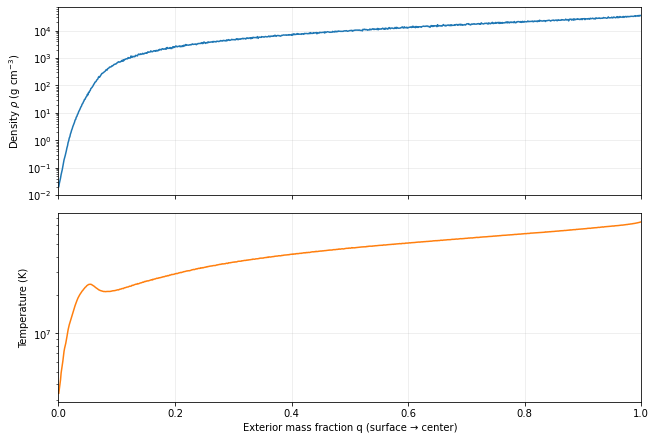

Verified 1000 rows, q = 0.000500 to 0.999500


In [4]:
import matplotlib.pyplot as plt
import numpy as np

with entropy_input_path.open() as profile:
    n_points = int(next(profile))
    saved = np.loadtxt(
        (line.replace("D", "E") for line in profile),
        ndmin=2,
    )

assert saved.shape == (n_points, 3)
np.testing.assert_allclose(saved, table, rtol=1e-14, atol=0)

q_out, rho_out, temperature_out = saved.T

fig, (ax_rho, ax_temp) = plt.subplots(
    2, 1, figsize=(9, 6), sharex=True, constrained_layout=True
)

ax_rho.semilogy(q_out, rho_out)
ax_rho.set_ylabel(r"Density $\rho$ (g cm$^{-3}$)")

ax_temp.semilogy(q_out, temperature_out, color="tab:orange")
ax_temp.set_ylabel("Temperature (K)")
ax_temp.set_xlabel("Exterior mass fraction q (surface → center)")

for ax in (ax_rho, ax_temp):
    ax.set_xlim(0, 1)
    ax.grid(True, alpha=0.25)

plt.show()

print("Verified {} rows, q = {:.6f} to {:.6f}".format(
    n_points, q_out[0], q_out[-1]
))